# Classificação da qualidade de vinhos

**Base utilizada:** `data/WineQT.csv`, arquivo disponibilizado no Kaggle por YasserH: [Wine Quality Dataset](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset).

O carregamento é feito por `src/data_loader.py`, usando um caminho relativo à estrutura do projeto. Ao executar todas as células, os gráficos e métricas são exportados para `results/`.


In [13]:
# Localiza a raiz do projeto sem depender da pasta de trabalho do computador.
from pathlib import Path
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "src" / "data_loader.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Abra este notebook dentro da pasta notebooks/ do projeto organizado.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_wine_data, DATASET_SOURCE, DATASET_SOURCE_URL
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import pandas as pd

# ==========================================
# ETAPA 1: COMPREENSÃO DO PROBLEMA
# ==========================================
# Objetivo: Carregar a base físico-química e criar a variável alvo de qualidade.

print("[INFO] Carregando a base de dados de vinhos...")
print(f"[FONTE] {DATASET_SOURCE}: {DATASET_SOURCE_URL}")
# Se o arquivo estiver dentro da pasta 'data', mude para 'data/WineQT.csv'
df_wine = load_wine_data() 

# Aplicando a regra de negócio da Fase 2: 
# Notas >= 7 são classificadas como "Vinho de Alta Qualidade" (1)
# Notas < 7 são classificadas como "Vinho de Baixa/Média Qualidade" (0)
# A função "where" do numpy/pandas é a forma mais limpa e otimizada de fazer isso
import numpy as np
df_wine['quality_binary'] = np.where(df_wine['quality'] >= 7, 1, 0)

# ==========================================
# ETAPA 2: ANÁLISE EXPLORATÓRIA (RESUMO)
# ==========================================
# Objetivo: Mostrar os dados gerais do dataset e o balanceamento da nova classe.

total_vinhos = len(df_wine)
vinhos_alta_qualidade = df_wine['quality_binary'].sum()
vinhos_comuns = total_vinhos - vinhos_alta_qualidade

percentual_alta = (vinhos_alta_qualidade / total_vinhos) * 100
percentual_comum = (vinhos_comuns / total_vinhos) * 100

print("\n" + "="*50)
print("🍷 RESUMO - QUALIDADE DO VINHO")
print("="*50)
print(f"Total de Amostras Analisadas: {total_vinhos}")
print(f"-> Vinhos de Baixa/Média Qualidade (< 7): {vinhos_comuns} ({percentual_comum:.1f}%)")
print(f"-> Vinhos de Alta Qualidade (>= 7):       {vinhos_alta_qualidade} ({percentual_alta:.1f}%)")
print("="*50)

print("\n[INFO] Visualizando as 5 primeiras linhas da base processada:")
display(df_wine.head())

[INFO] Carregando a base de dados de vinhos...
[FONTE] Kaggle — YasserH, Wine Quality Dataset (arquivo WineQT.csv): https://www.kaggle.com/datasets/yasserh/wine-quality-dataset

🍷 RESUMO - QUALIDADE DO VINHO
Total de Amostras Analisadas: 1143
-> Vinhos de Baixa/Média Qualidade (< 7): 984 (86.1%)
-> Vinhos de Alta Qualidade (>= 7):       159 (13.9%)

[INFO] Visualizando as 5 primeiras linhas da base processada:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,quality_binary
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4,0


[INFO] Processando a base de dados...

📊 INSIGHTS DA ANÁLISE EXPLORATÓRIA
1. BALANCEAMENTO DE CLASSES (O Tamanho do Desafio):
   Apenas 13.9% da produção atinge nota >= 7.
   Temos um desbalanceamento severo: 984 vinhos comuns vs 159 premium.
   *Impacto:* Nossos modelos de ML precisarão de técnicas para lidar com essa minoria.

2. ASSOCIAÇÕES OBSERVADAS COM A QUALIDADE:
   -> Maior associação positiva: 'alcohol' (correlação: 0.40)
   -> Maior associação negativa: 'volatile acidity' (correlação: -0.30)
   Essas relações descrevem este conjunto de dados; correlação não demonstra causa.
   A matriz completa e as estatísticas descritivas estão exibidas abaixo.


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.31,1.75,4.60,7.10,7.90,9.10,15.90
volatile acidity,1143.0,0.53,0.18,0.12,0.39,0.52,0.64,1.58
citric acid,1143.0,0.27,0.20,0.00,0.09,0.25,0.42,1.00
residual sugar,1143.0,2.53,1.36,0.90,1.90,2.20,2.60,15.50
chlorides,1143.0,0.09,0.05,0.01,0.07,0.08,0.09,0.61
free sulfur dioxide,1143.0,15.62,10.25,1.00,7.00,13.00,21.00,68.00
total sulfur dioxide,1143.0,45.91,32.78,6.00,21.00,37.00,61.00,289.00
density,1143.0,1.00,0.00,0.99,1.00,1.00,1.00,1.00
pH,1143.0,3.31,0.16,2.74,3.20,3.31,3.40,4.01
sulphates,1143.0,0.66,0.17,0.33,0.55,0.62,0.73,2.00


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality_binary
fixed acidity,1.00,-0.25,0.67,0.17,0.11,-0.16,-0.11,0.68,-0.69,0.17,-0.08,0.12
volatile acidity,-0.25,1.00,-0.54,-0.01,0.06,-0.00,0.08,0.02,0.22,-0.28,-0.20,-0.30
citric acid,0.67,-0.54,1.00,0.18,0.25,-0.06,0.04,0.38,-0.55,0.33,0.11,0.25
residual sugar,0.17,-0.01,0.18,1.00,0.07,0.17,0.19,0.38,-0.12,0.02,0.06,0.06
chlorides,0.11,0.06,0.25,0.07,1.00,0.02,0.05,0.21,-0.28,0.37,-0.23,-0.10
free sulfur dioxide,-0.16,-0.00,-0.06,0.17,0.02,1.00,0.66,-0.05,0.07,0.03,-0.05,-0.06
total sulfur dioxide,-0.11,0.08,0.04,0.19,0.05,0.66,1.00,0.05,-0.06,0.03,-0.19,-0.11
density,0.68,0.02,0.38,0.38,0.21,-0.05,0.05,1.00,-0.35,0.14,-0.49,-0.15
pH,-0.69,0.22,-0.55,-0.12,-0.28,0.07,-0.06,-0.35,1.00,-0.19,0.23,-0.07
sulphates,0.17,-0.28,0.33,0.02,0.37,0.03,0.03,0.14,-0.19,1.00,0.09,0.21



3. POSSÍVEIS OUTLIERS (CRITÉRIO IQR):
   A tabela mostra quantas amostras ficam fora de 1,5 × IQR em cada variável.
   Esses casos são sinais para investigação; não significam automaticamente erro de medição.


,Amostras sinalizadas
residual sugar,110
chlorides,77
fixed acidity,44
sulphates,43
total sulfur dioxide,40
density,36
pH,20
free sulfur dioxide,18
volatile acidity,14
alcohol,12



[INFO] Gerando o Dashboard Executivo da Análise...


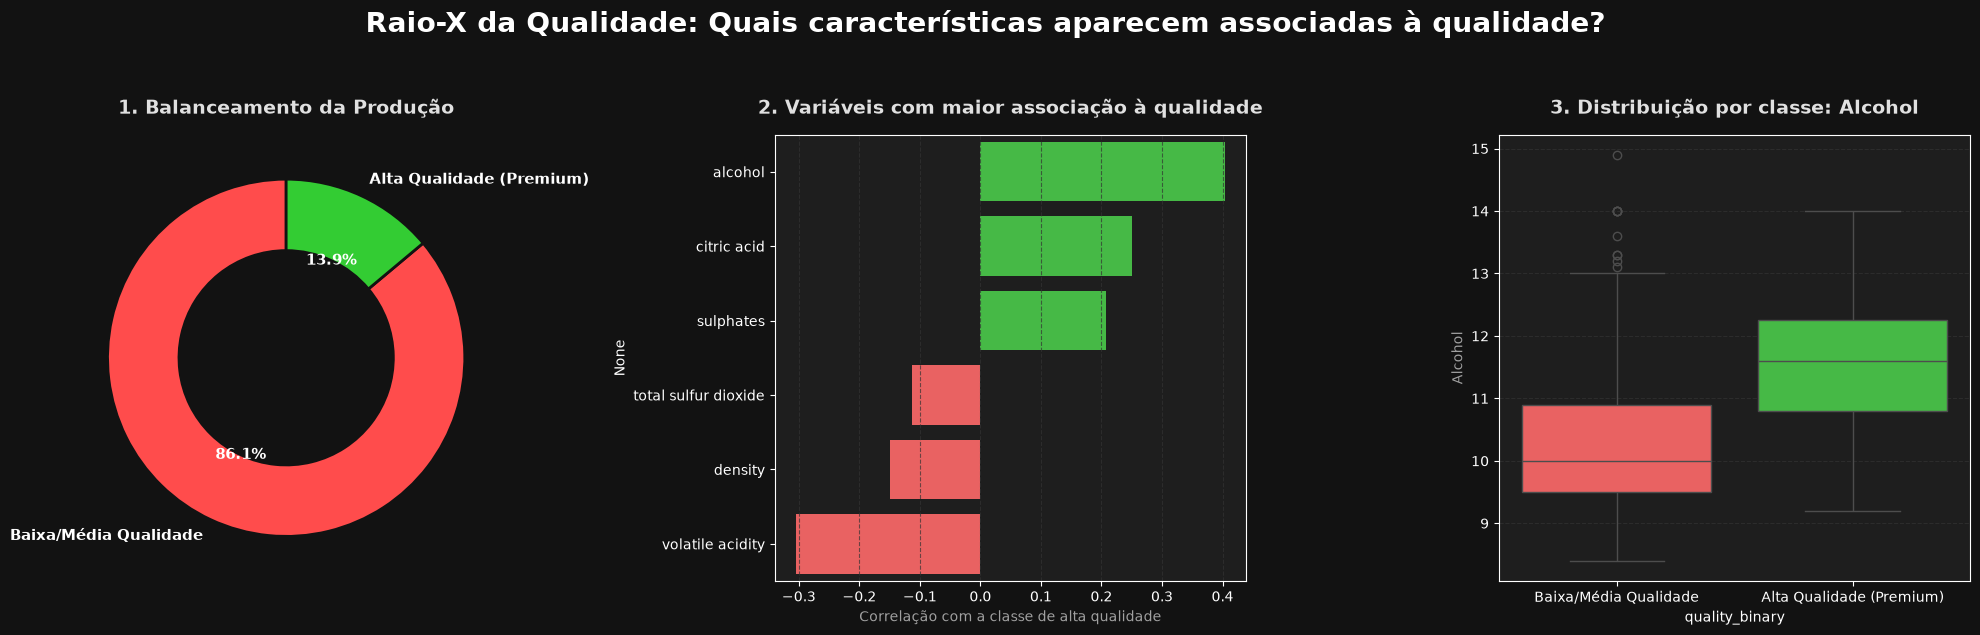

In [14]:
# ==========================================
# ETAPA 2: ANÁLISE EXPLORATÓRIA DE DADOS (EDA)
# Foco Executivo: explorar características associadas à qualidade
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Ignorando avisos estéticos e configurando tema escuro (padrão executivo)
warnings.filterwarnings("ignore")
plt.rcParams['toolbar'] = 'None'
plt.style.use('dark_background')

# 1. Carregando os dados e aplicando a Regra de Negócio
print("[INFO] Processando a base de dados...")
df_wine = load_wine_data()
df_wine['quality_binary'] = np.where(df_wine['quality'] >= 7, 1, 0)

# 2. Analisando o Balanceamento (Variável Alvo)
total = len(df_wine)
alta_qualidade = df_wine['quality_binary'].sum()
baixa_qualidade = total - alta_qualidade
pct_alta = (alta_qualidade / total) * 100

# 3. Calculando associações observadas entre as variáveis
# Removemos 'quality', 'quality_binary' e 'Id' (se existir) para focar apenas nas químicas
colunas_ignoradas = ['quality', 'quality_binary', 'Id']
features = [col for col in df_wine.columns if col not in colunas_ignoradas]
correlacoes = df_wine[features + ['quality_binary']].corr()['quality_binary'].drop('quality_binary').sort_values(ascending=False)

top_positiva = correlacoes.idxmax()
top_negativa = correlacoes.idxmin()

# Resumo das distribuições e matriz de correlação para apoiar a análise exploratória
resumo_distribuicao = df_wine[features].describe().T.round(2)
matriz_correlacao = df_wine[features + ['quality_binary']].corr().round(2)

# Sinalização estatística de possíveis outliers pelo critério do intervalo interquartil (IQR)
q1 = df_wine[features].quantile(0.25)
q3 = df_wine[features].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
contagem_outliers_iqr = ((df_wine[features] < limite_inferior) | (df_wine[features] > limite_superior)).sum().sort_values(ascending=False)

# ==========================================
# EXIBIÇÃO DE INSIGHTS NO TERMINAL (STORYTELLING)
# ==========================================
print("\n" + "="*60)
print("📊 INSIGHTS DA ANÁLISE EXPLORATÓRIA")
print("="*60)
print("1. BALANCEAMENTO DE CLASSES (O Tamanho do Desafio):")
print(f"   Apenas {pct_alta:.1f}% da produção atinge nota >= 7.")
print(f"   Temos um desbalanceamento severo: {baixa_qualidade} vinhos comuns vs {alta_qualidade} premium.")
print("   *Impacto:* Nossos modelos de ML precisarão de técnicas para lidar com essa minoria.")

print("\n2. ASSOCIAÇÕES OBSERVADAS COM A QUALIDADE:")
print(f"   -> Maior associação positiva: '{top_positiva}' (correlação: {correlacoes[top_positiva]:.2f})")
print(f"   -> Maior associação negativa: '{top_negativa}' (correlação: {correlacoes[top_negativa]:.2f})")
print("   Essas relações descrevem este conjunto de dados; correlação não demonstra causa.")
print("   A matriz completa e as estatísticas descritivas estão exibidas abaixo.")
display(resumo_distribuicao)
display(matriz_correlacao)

print("\n3. POSSÍVEIS OUTLIERS (CRITÉRIO IQR):")
print("   A tabela mostra quantas amostras ficam fora de 1,5 × IQR em cada variável.")
print("   Esses casos são sinais para investigação; não significam automaticamente erro de medição.")
display(contagem_outliers_iqr.rename('Amostras sinalizadas').to_frame())

print("="*60)
print("\n[INFO] Gerando o Dashboard Executivo da Análise...")

# ==========================================
# DASHBOARD VISUAL - TELA ÚNICA
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.patch.set_facecolor('#121212') # Cor de fundo da janela

fig.suptitle('Raio-X da Qualidade: Quais características aparecem associadas à qualidade?', 
             fontsize=20, fontweight='bold', color='white', y=1.05)

# --- Gráfico 1: Balanceamento (Donut Chart) ---
cores_classes = ['#ff4c4c', '#33cc33'] # Vermelho (Comum) e Verde (Premium)
labels = ['Baixa/Média Qualidade', 'Alta Qualidade (Premium)']
axes[0].pie(
    [baixa_qualidade, alta_qualidade], 
    labels=labels,
    autopct='%1.1f%%',
    startangle=90, 
    colors=cores_classes,
    textprops={'color': "w", 'weight': 'bold', 'fontsize': 11},
    wedgeprops=dict(width=0.4, edgecolor='#121212', linewidth=2)
)
axes[0].set_title('1. Balanceamento da Produção', fontsize=14, color='#e0e0e0', fontweight='bold', pad=15)

# --- Gráfico 2: Top Correlações (Bar Chart) ---
# Pegando as 3 mais positivas e as 3 mais negativas
top_features = pd.concat([correlacoes.head(3), correlacoes.tail(3)])
cores_barras = ['#33cc33' if val > 0 else '#ff4c4c' for val in top_features.values]

sns.barplot(x=top_features.values, y=top_features.index, ax=axes[1], palette=cores_barras)
axes[1].set_title('2. Variáveis com maior associação à qualidade', fontsize=14, color='#e0e0e0', fontweight='bold', pad=15)
axes[1].set_xlabel('Correlação com a classe de alta qualidade', fontsize=10, color='#a0a0a0')
axes[1].set_facecolor('#1e1e1e')
axes[1].grid(axis='x', color='#333333', linestyle='--', alpha=0.7)

# --- Gráfico 3: Distribuição por classe (Boxplot da variável mais associada) ---
sns.boxplot(x='quality_binary', y=top_positiva, data=df_wine, ax=axes[2], palette=['#ff4c4c', '#33cc33'])
axes[2].set_title(f'3. Distribuição por classe: {top_positiva.title()}', fontsize=14, color='#e0e0e0', fontweight='bold', pad=15)
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Baixa/Média Qualidade', 'Alta Qualidade (Premium)'], color='white')
axes[2].set_ylabel(top_positiva.title(), fontsize=10, color='#a0a0a0')
axes[2].set_facecolor('#1e1e1e')
axes[2].grid(axis='y', color='#333333', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [15]:
# ==========================================
# ETAPA 3: PRÉ-PROCESSAMENTO DE DADOS
# Foco: preparar as variáveis sem usar informações do conjunto de teste
# ==========================================
import pandas as pd
import numpy as np

# Recarregando a base e aplicando a regra de negócio
df_wine = load_wine_data()
df_wine['quality_binary'] = np.where(df_wine['quality'] >= 7, 1, 0)

print("\n" + "="*60)
print("⚙️  RESUMO DO PRÉ-PROCESSAMENTO (PREPARAÇÃO DOS DADOS)")
print("="*60)

# --- 1. VERIFICAÇÃO DE DADOS FALTANTES ---
dados_faltantes = int(df_wine.isnull().sum().sum())
if dados_faltantes > 0:
    print(f"[INFO] Encontramos {dados_faltantes} dados faltantes. A mediana será aprendida apenas nos dados de treino.")
else:
    print("[OK] 1. Tratamento de Nulos: a base não possui valores faltantes.")

# --- 2. CRIAÇÃO DE NOVA FEATURE (FEATURE ENGINEERING) ---
# Variável candidata para análise: proporção de SO2 livre em relação ao total.
# Quando o total é zero ou há valor ausente, a razão fica ausente e será tratada no pipeline.
so2_total = df_wine['total sulfur dioxide']
so2_livre = df_wine['free sulfur dioxide']
df_wine['razao_so2'] = np.divide(
    so2_livre,
    so2_total,
    out=np.full(len(df_wine), np.nan, dtype=float),
    where=so2_total.notna() & so2_total.ne(0) & so2_livre.notna()
)
print("[OK] 2. Engenharia de Features: variável candidata 'razao_so2' criada; divisão por zero/ausências tratadas.")

# --- 3. DEFINIÇÃO DAS VARIÁVEIS ---
# O Id é identificador, e a nota original não pode entrar como variável explicativa
# porque ela própria define o alvo binário.
colunas_para_remover = ['quality', 'quality_binary']
if 'Id' in df_wine.columns:
    colunas_para_remover.append('Id')

X_bruto = df_wine.drop(columns=colunas_para_remover)
y_alvo = df_wine['quality_binary']

print("[OK] 3. Variáveis explicativas e alvo definidos.")
print("[INFO] Imputação e padronização serão ajustadas dentro do pipeline, usando somente os dados de treino.")
print("="*60)
print("\n🔍 AMOSTRA DAS VARIÁVEIS ANTES DA PADRONIZAÇÃO:")
display(X_bruto.head())
print("\n✅ Dados preparados para a divisão entre treino e teste.")


⚙️  RESUMO DO PRÉ-PROCESSAMENTO (PREPARAÇÃO DOS DADOS)
[OK] 1. Tratamento de Nulos: a base não possui valores faltantes.
[OK] 2. Engenharia de Features: variável candidata 'razao_so2' criada; divisão por zero/ausências tratadas.
[OK] 3. Variáveis explicativas e alvo definidos.
[INFO] Imputação e padronização serão ajustadas dentro do pipeline, usando somente os dados de treino.

🔍 AMOSTRA DAS VARIÁVEIS ANTES DA PADRONIZAÇÃO:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,razao_so2
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0.323529
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0.373134
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0.277778
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,0.283333
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0.323529



✅ Dados preparados para a divisão entre treino e teste.


In [16]:
# ==========================================
# ETAPA 4: DESENVOLVIMENTO DOS MODELOS DE ML
# Foco: Treinando a IA para prever a qualidade do vinho
# ==========================================
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

print("\n" + "="*60)
print("🤖 TREINAMENTO DA INTELIGÊNCIA ARTIFICIAL (MACHINE LEARNING)")
print("="*60)

# --- 1. DIVISÃO DOS DADOS (TREINO VS TESTE) ---
# A regra de ouro de Machine Learning: Nunca teste o modelo com os mesmos dados 
# que ele usou para aprender (senão ele "decora" a resposta ao invés de aprender).
# Vamos separar 80% dos dados para a IA treinar (estudar) e 20% para a prova final (testar).

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X_bruto,       # Variáveis originais; transformações são aprendidas somente no treino
    y_alvo,        # A resposta certa (0 ou 1)
    test_size=0.20, # 20% para o teste
    random_state=42, # Semente fixa para garantir que o resultado seja o mesmo toda vez
    stratify=y_alvo  # Como temos poucos vinhos Premium, isso garante que a proporção de 13% seja mantida nas duas partes
)

print(f"[INFO] Base dividida: {len(X_treino)} amostras para treino, {len(X_teste)} amostras para teste.")

# --- 2. TREINANDO O MODELO 1: REGRESSÃO LOGÍSTICA ---
print("\n[INFO] Treinando o Modelo 1 (Regressão Logística)...")
modelo_lr = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(random_state=42, class_weight='balanced')
)
# class_weight='balanced' atribui pesos inversamente proporcionais à frequência das classes.
modelo_lr.fit(X_treino, y_treino)

# --- 3. TREINANDO O MODELO 2: SVM (SUPPORT VECTOR MACHINE) ---
print("[INFO] Treinando o Modelo 2 (Support Vector Machine - SVM)...")
modelo_svm = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    SVC(kernel='linear', random_state=42, class_weight='balanced')
)
# O kernel linear é uma escolha inicial simples para comparação entre classificadores.
modelo_svm.fit(X_treino, y_treino)

# --- 4. FAZENDO PREVISÕES NA BASE DE TESTE ---
# Agora a IA faz a "prova final" (tenta adivinhar os vinhos dos 20% que separamos)
previsoes_lr = modelo_lr.predict(X_teste)
previsoes_svm = modelo_svm.predict(X_teste)

# Amostra ilustrativa: scaler ajustado no treino e aplicado a dados de teste
scaler_treino = modelo_lr.named_steps['standardscaler']
comparacao = pd.DataFrame({
    'Valor Bruto (Original)': X_teste['total sulfur dioxide'].head(),
    'Valor Padronizado (Scaler ajustado no treino)': scaler_treino.transform(
        modelo_lr.named_steps['simpleimputer'].transform(X_teste.head())
    )[:, list(X_bruto.columns).index('total sulfur dioxide')][:5]
})
print("\n🔍 EXEMPLO DE PADRONIZAÇÃO: parâmetros aprendidos no treino e aplicados ao teste")
display(comparacao)

print("\n✅ Treinamento concluído com sucesso!")
print("Os dois modelos estudaram a química dos vinhos e já tentaram classificar o lote de teste.")
print("="*60)
print("\nPreparando a Avaliação (Etapa 5) para vermos qual 'Chef' se saiu melhor...")


🤖 TREINAMENTO DA INTELIGÊNCIA ARTIFICIAL (MACHINE LEARNING)
[INFO] Base dividida: 914 amostras para treino, 229 amostras para teste.

[INFO] Treinando o Modelo 1 (Regressão Logística)...
[INFO] Treinando o Modelo 2 (Support Vector Machine - SVM)...

🔍 EXEMPLO DE PADRONIZAÇÃO: parâmetros aprendidos no treino e aplicados ao teste


,Valor Bruto (Original),Valor Padronizado (Scaler ajustado no treino)
636,39.0,-0.189045
1004,22.0,-0.701141
162,106.0,1.829214
640,78.0,0.985763
448,43.0,-0.068552



✅ Treinamento concluído com sucesso!
Os dois modelos estudaram a química dos vinhos e já tentaram classificar o lote de teste.

Preparando a Avaliação (Etapa 5) para vermos qual 'Chef' se saiu melhor...



⚖️ AVALIAÇÃO DE DESEMPENHO E COMPARAÇÃO DE MODELOS
--- Desempenho: Regressão Logística ---
🔹 Acurácia Global: 79.0% (Taxa geral de acertos)
🔹 Precisão:        36.2% (Quando diz que é Premium, acerta nesta proporção)
🔹 Recall:          65.6% (Dos vinhos que realmente eram Premium, encontrou esta proporção)
🔹 F1-Score:        46.7% (Média equilibrada entre Precisão e Recall)

--- Desempenho: Support Vector Machine (SVM) ---
🔹 Acurácia Global: 78.2% (Taxa geral de acertos)
🔹 Precisão:        35.5% (Quando diz que é Premium, acerta nesta proporção)
🔹 Recall:          68.8% (Dos vinhos que realmente eram Premium, encontrou esta proporção)
🔹 F1-Score:        46.8% (Média equilibrada entre Precisão e Recall)



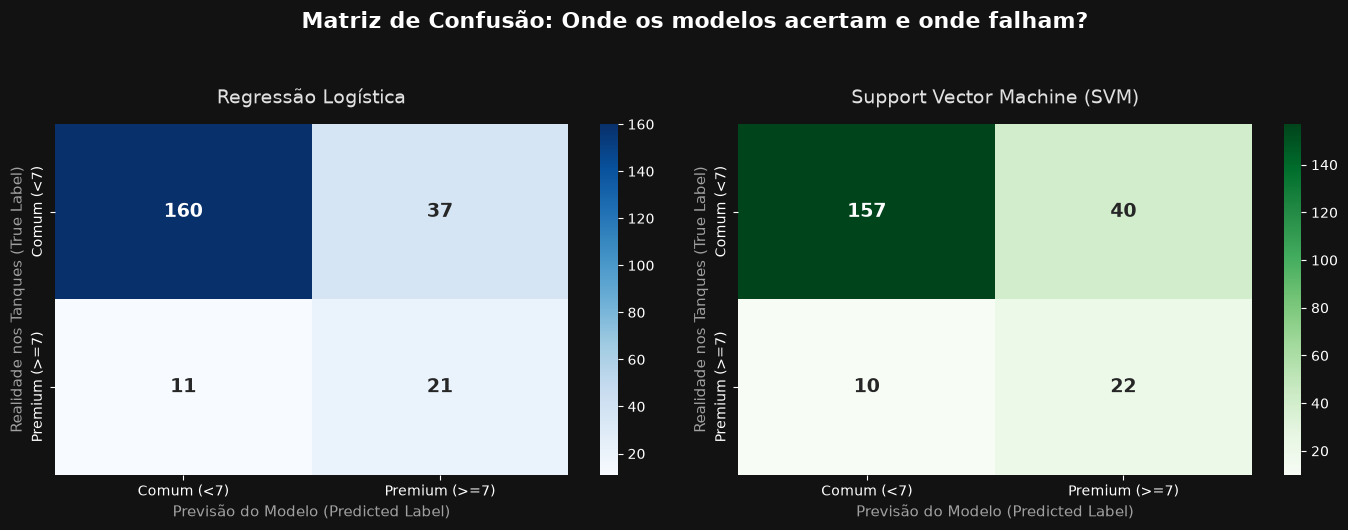

In [17]:
# ==========================================
# ETAPA 5: AVALIAÇÃO DOS MODELOS
# Foco: Qual modelo traz mais valor para a vinícola?
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("\n" + "="*60)
print("⚖️ AVALIAÇÃO DE DESEMPENHO E COMPARAÇÃO DE MODELOS")
print("="*60)

# Função para calcular e exibir as métricas de forma executiva
def calcular_metricas(y_verdadeiro, y_previsto, nome_modelo):
    acc = accuracy_score(y_verdadeiro, y_previsto)
    prec = precision_score(y_verdadeiro, y_previsto, zero_division=0)
    rec = recall_score(y_verdadeiro, y_previsto, zero_division=0)
    f1 = f1_score(y_verdadeiro, y_previsto, zero_division=0)
    
    print(f"--- Desempenho: {nome_modelo} ---")
    print(f"🔹 Acurácia Global: {acc:.1%} (Taxa geral de acertos)")
    print(f"🔹 Precisão:        {prec:.1%} (Quando diz que é Premium, acerta nesta proporção)")
    print(f"🔹 Recall:          {rec:.1%} (Dos vinhos que realmente eram Premium, encontrou esta proporção)")
    print(f"🔹 F1-Score:        {f1:.1%} (Média equilibrada entre Precisão e Recall)\n")
    
    return [acc, prec, rec, f1]

# Calculando para os dois modelos
metricas_lr = calcular_metricas(y_teste, previsoes_lr, "Regressão Logística")
metricas_svm = calcular_metricas(y_teste, previsoes_svm, "Support Vector Machine (SVM)")

# ==========================================
# VISUALIZAÇÃO: MATRIZ DE CONFUSÃO (DARK MODE)
# ==========================================
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#121212')

fig.suptitle('Matriz de Confusão: Onde os modelos acertam e onde falham?', 
             fontsize=16, fontweight='bold', color='white', y=1.05)

labels_matriz = ['Comum (<7)', 'Premium (>=7)']

# Plot Matriz 1: Regressão Logística
cm_lr = confusion_matrix(y_teste, previsoes_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            xticklabels=labels_matriz, yticklabels=labels_matriz, annot_kws={"size": 14, "weight": "bold"})
axes[0].set_title('Regressão Logística', fontsize=14, color='#e0e0e0', pad=15)
axes[0].set_ylabel('Realidade nos Tanques (True Label)', fontsize=11, color='#a0a0a0')
axes[0].set_xlabel('Previsão do Modelo (Predicted Label)', fontsize=11, color='#a0a0a0')

# Plot Matriz 2: SVM
cm_svm = confusion_matrix(y_teste, previsoes_svm)

# Exporta métricas e contagens para consulta rápida fora do notebook.
metricas_resultado = pd.DataFrame([
    {"modelo": "Regressão Logística", "n_teste": len(y_teste),
     "tn": int(cm_lr[0, 0]), "fp": int(cm_lr[0, 1]), "fn": int(cm_lr[1, 0]), "tp": int(cm_lr[1, 1]),
     "acuracia": metricas_lr[0], "precisao": metricas_lr[1], "recall": metricas_lr[2], "f1": metricas_lr[3]},
    {"modelo": "SVM linear", "n_teste": len(y_teste),
     "tn": int(cm_svm[0, 0]), "fp": int(cm_svm[0, 1]), "fn": int(cm_svm[1, 0]), "tp": int(cm_svm[1, 1]),
     "acuracia": metricas_svm[0], "precisao": metricas_svm[1], "recall": metricas_svm[2], "f1": metricas_svm[3]},
])
metricas_resultado.to_csv(RESULTS_DIR / "metricas_modelos.csv", index=False, encoding="utf-8")
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens', ax=axes[1], 
            xticklabels=labels_matriz, yticklabels=labels_matriz, annot_kws={"size": 14, "weight": "bold"})
axes[1].set_title('Support Vector Machine (SVM)', fontsize=14, color='#e0e0e0', pad=15)
axes[1].set_ylabel('Realidade nos Tanques (True Label)', fontsize=11, color='#a0a0a0')
axes[1].set_xlabel('Previsão do Modelo (Predicted Label)', fontsize=11, color='#a0a0a0')

plt.tight_layout()
plt.show()


🧠 VARIÁVEIS ASSOCIADAS ÀS PREVISÕES DO MODELO

🟢 MAIORES COEFICIENTES POSITIVOS (associação com previsão Premium):
   -> Alcohol (coeficiente: 1.00)
   -> Sulphates (coeficiente: 0.70)
   -> Citric Acid (coeficiente: 0.48)

🔴 MAIORES COEFICIENTES NEGATIVOS (associação com previsão não Premium):
   -> Volatile Acidity (coeficiente: -0.47)
   -> Chlorides (coeficiente: -0.45)
   -> Total Sulfur Dioxide (coeficiente: -0.21)


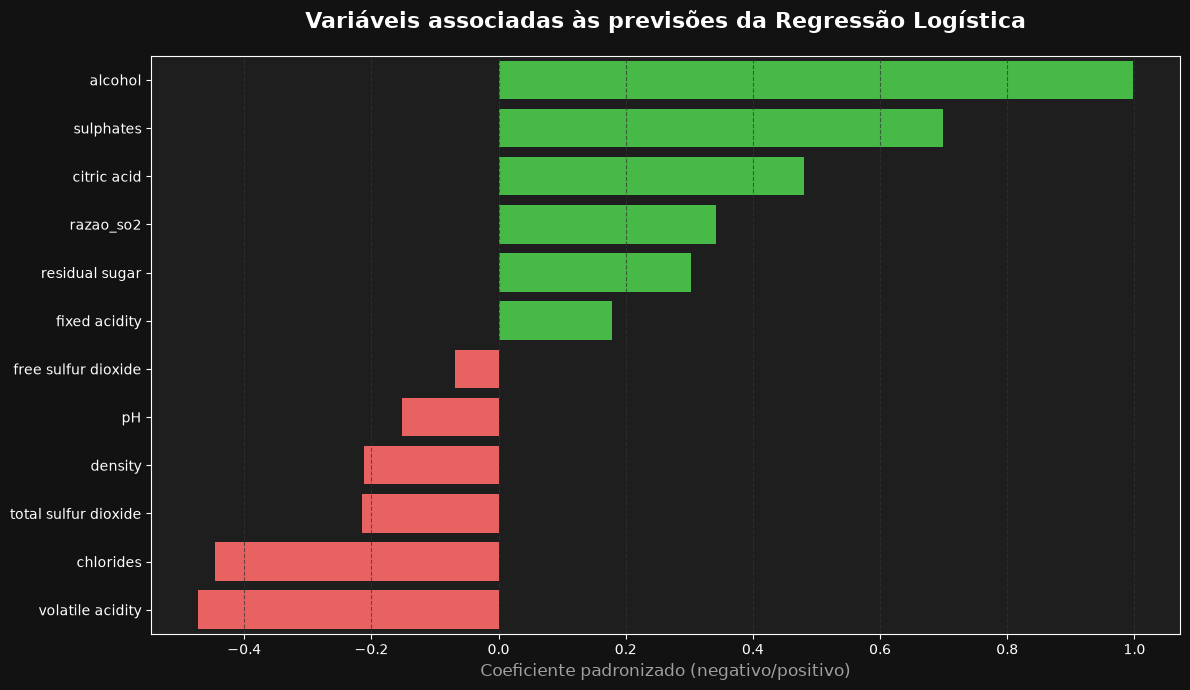


Nota: os sinais e magnitudes descrevem associações do modelo; não provam que uma variável cause mudança na qualidade.


In [18]:
# ==========================================
# ETAPA 6: INTERPRETAÇÃO DOS RESULTADOS
# Foco: quais variáveis ficaram associadas às previsões do modelo?
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "="*60)
print("🧠 VARIÁVEIS ASSOCIADAS ÀS PREVISÕES DO MODELO")
print("="*60)

# Coeficientes da Regressão Logística ajustada sobre variáveis padronizadas no treino
importancias = modelo_lr.named_steps['logisticregression'].coef_[0]
nomes_features = X_bruto.columns

# Criando um ranking de importância
df_importancia = pd.DataFrame({'Característica': nomes_features, 'Coeficiente': importancias})
df_importancia = df_importancia.sort_values(by='Coeficiente', ascending=False)

top_positivos = df_importancia.head(3)
top_negativos = df_importancia.tail(3)

print("\n🟢 MAIORES COEFICIENTES POSITIVOS (associação com previsão Premium):")
for _, row in top_positivos.iterrows():
    print(f"   -> {row['Característica'].title()} (coeficiente: {row['Coeficiente']:.2f})")

print("\n🔴 MAIORES COEFICIENTES NEGATIVOS (associação com previsão não Premium):")
for _, row in top_negativos.sort_values(by='Coeficiente').iterrows():
    print(f"   -> {row['Característica'].title()} (coeficiente: {row['Coeficiente']:.2f})")

# ==========================================
# DASHBOARD FINAL: IMPACTO DAS VARIÁVEIS
# ==========================================
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor('#121212')
ax.set_facecolor('#1e1e1e')

# Cores indicam o sinal dos coeficientes; não representam relações causais
cores = ['#33cc33' if val > 0 else '#ff4c4c' for val in df_importancia['Coeficiente']]

sns.barplot(x='Coeficiente', y='Característica', data=df_importancia, palette=cores, ax=ax)
ax.set_title('Variáveis associadas às previsões da Regressão Logística', fontsize=16, color='white', fontweight='bold', pad=20)
ax.set_xlabel('Coeficiente padronizado (negativo/positivo)', fontsize=12, color='#a0a0a0')
ax.set_ylabel('')
ax.grid(axis='x', color='#333333', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print("\nNota: os sinais e magnitudes descrevem associações do modelo; não provam que uma variável cause mudança na qualidade.")